# Unsupervised learning: clustering African countries by development indicators

**Goal:** group African countries into clusters of similar development profiles, using World Bank data and K-Means, and see where Kenya lands.

There are no labels here, so this is *unsupervised*: the algorithm finds structure on its own and I have to interpret it myself.

This first part covers data preparation.

## 1. Which countries?

I use **all 54 African countries**, not only Sub-Saharan Africa. The World Bank's "Sub-Saharan Africa" group has 48 countries. It classes Algeria, Djibouti, Egypt, Libya, Morocco and Tunisia under the Middle East & North Africa region, so I add those six to get all 54. Using the whole continent gives more countries (more data for clustering) and lets the model show whether the North African countries form their own group.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wbgapi as wb
from sklearn.preprocessing import StandardScaler

# 48 Sub-Saharan countries (World Bank region code "SSF") + 6 others World Bank files under MENA
north_and_djibouti = ["DZA", "DJI", "EGY", "LBY", "MAR", "TUN"]
country_codes = list(wb.region.members("SSF")) + north_and_djibouti

# Safety check: I expect exactly 54 distinct countries
assert len(set(country_codes)) == 54, "expected 54 African countries"
print(len(country_codes), "countries")

54 countries


## 2. Fetch the indicators and average over 2018-2022

I download eight indicators. I average each over 2018-2022 for two reasons: a single year can be missing or unusual, and averaging five years gives a more stable picture. (2020-2021 include COVID effects, which averaging softens but does not remove.)

In [2]:
# World Bank indicator code -> short readable column name
indicators = {
    "NY.GDP.PCAP.CD": "gdp_per_capita",          # GDP per capita, current US$
    "SP.DYN.LE00.IN": "life_expectancy",         # years
    "SH.DYN.MORT": "under5_mortality",           # deaths per 1,000 live births
    "SP.DYN.TFRT.IN": "fertility_rate",          # births per woman
    "EG.ELC.ACCS.ZS": "electricity_access",      # % of population
    "IT.NET.USER.ZS": "internet_users",          # % of population
    "SP.URB.TOTL.IN.ZS": "urban_population",     # % of population
    "NV.AGR.TOTL.ZS": "agriculture_share_gdp",   # agriculture, % of GDP
}

# Rows = (country, indicator), columns = one per year 2018..2022
raw_by_year = wb.data.DataFrame(list(indicators.keys()), economy=country_codes, time=range(2018, 2023))
print(raw_by_year.shape)
raw_by_year.head(8)

(432, 5)


YR2018       YR2019       YR2020       YR2021  \
economy series                                                                  
AGO     EG.ELC.ACCS.ZS       45.300000    45.600000    47.000000    48.200000   
        IT.NET.USER.ZS       29.000000    32.129398    33.320900    34.556499   
        NV.AGR.TOTL.ZS       13.193392    12.321051    15.109767    16.831797   
        NY.GDP.PCAP.CD     2891.830324  2507.868072  1749.179484  2266.968349   
        SH.DYN.MORT          56.500000    55.300000    54.200000    53.200000   
        SP.DYN.LE00.IN       62.622000    63.051000    63.116000    62.958000   
        SP.DYN.TFRT.IN        5.519000     5.442000     5.371000     5.304000   
        SP.URB.TOTL.IN.ZS    65.873214    66.663782    67.456827    68.252416   

                                YR2022  
economy series                          
AGO     EG.ELC.ACCS.ZS       48.500000  
        IT.NET.USER.ZS       35.838001  
        NV.AGR.TOTL.ZS       19.430117  
        NY.GDP.PCAP.CD     3598.536691  
        SH.DYN.MORT          51.900000  
        SP.DYN.LE00.IN       64.246000  
        SP.DYN.TFRT.IN        5.209000  
        SP.URB.TOTL.IN.ZS    69.050619

In [3]:
# Average over the 5 years. mean() skips missing years, so a country with 3 of 5 years
# is averaged over those 3 years (one reason to treat these numbers as approximate).
averaged = raw_by_year.mean(axis=1)           # one value per (country, indicator)
countries = averaged.unstack("series")        # turn indicators into columns: one row per country
countries = countries.rename(columns=indicators)
countries.index.name = "iso3"

# Add readable country names (only for display later)
country_names = wb.economy.DataFrame().loc[country_codes, "name"]
countries.insert(0, "country", country_names)

# Save the raw (unimputed, untransformed) data so the analysis can be repeated offline
countries.to_csv("../data/africa_indicators_2018_2022_raw.csv")
print(countries.shape)
countries.head()

(54, 9)


series,country,electricity_access,internet_users,agriculture_share_gdp,gdp_per_capita,under5_mortality,life_expectancy,fertility_rate,urban_population
iso3,,,,,,,,,
AGO,Angola,46.92,32.968960,15.377225,2602.876584,54.22,63.1986,5.3690,67.459372
BDI,Burundi,9.78,6.088920,34.006528,259.735969,54.32,62.3076,5.1772,19.966066
BEN,Benin,43.70,24.072720,27.495076,1213.567056,84.56,59.9674,4.8134,49.462574
BFA,Burkina Faso,17.80,14.858981,19.010627,818.084373,85.28,60.2712,4.5356,26.530070
BWA,Botswana,71.96,51.845359,1.955438,7407.988693,38.58,66.6466,2.8640,66.408232


## 3. Missing values

The rule I set: **drop a country if it is missing more than 2 of the 8 indicators** (too little information to place it), and **fill the remaining gaps with the median** of that indicator. I use the median, not the mean, because several indicators are skewed (GDP especially) and the median is not pulled around by a few extreme countries.

In [4]:
feature_cols = list(indicators.values())

# How many countries are missing each indicator?
print("Missing per indicator:")
print(countries[feature_cols].isna().sum())

# How many indicators is each country missing?
missing_per_country = countries[feature_cols].isna().sum(axis=1)
print()
print("Countries with any missing indicator:")
countries.loc[missing_per_country > 0, ["country"] + feature_cols]

Missing per indicator:
series
gdp_per_capita           2
life_expectancy          0
under5_mortality         0
fertility_rate           0
electricity_access       0
internet_users           1
urban_population         0
agriculture_share_gdp    3
dtype: int64

Countries with any missing indicator:


series,country,gdp_per_capita,life_expectancy,under5_mortality,fertility_rate,electricity_access,internet_users,urban_population,agriculture_share_gdp
iso3,,,,,,,,,
ERI,Eritrea,NaN,67.1988,39.18,3.9278,51.74,10.288733,35.106104,NaN
SDN,Sudan,755.432166,65.3166,54.38,4.5362,59.52,NaN,34.555482,21.84
SOM,"Somalia, Fed. Rep.",537.962277,55.7490,124.72,6.4566,49.60,17.307475,52.257227,NaN
SSD,South Sudan,NaN,56.3864,104.10,4.1602,7.30,5.735500,20.195885,NaN


In [5]:
# Drop countries missing MORE than 2 indicators
too_much_missing = missing_per_country > 2
dropped = countries.loc[too_much_missing, "country"]
print("Countries dropped:", list(dropped) if len(dropped) > 0 else "none (no country is missing more than 2 indicators)")

countries_kept = countries.loc[~too_much_missing].copy()

# Median-impute the remaining gaps (median of each indicator over the kept countries)
medians = countries_kept[feature_cols].median()
countries_clean = countries_kept.copy()
countries_clean[feature_cols] = countries_kept[feature_cols].fillna(medians)

# Show exactly what was filled in, so the imputation is transparent
filled = countries_kept[feature_cols].isna()
for iso3, column in zip(*np.where(filled)):
    code = countries_kept.index[iso3]
    name = feature_cols[column]
    print(f"{code}: {name} missing -> filled with median {medians[name]:.2f}")

print()
print("Missing values left:", countries_clean[feature_cols].isna().sum().sum())
print("Countries kept:", len(countries_clean))

Countries dropped: none (no country is missing more than 2 indicators)
ERI: gdp_per_capita missing -> filled with median 1522.57
ERI: agriculture_share_gdp missing -> filled with median 18.70
SDN: internet_users missing -> filled with median 28.93
SOM: agriculture_share_gdp missing -> filled with median 18.70
SSD: gdp_per_capita missing -> filled with median 1522.57
SSD: agriculture_share_gdp missing -> filled with median 18.70

Missing values left: 0
Countries kept: 54


## 4. Log-transform GDP per capita

GDP per capita is very right-skewed: a few rich countries (like Seychelles or Mauritius) have values many times larger than most others. K-Means uses distances, so those few extreme values would dominate. A log transform compresses the long tail and makes differences *proportional* (going from $500 to $1,000 counts the same as $5,000 to $10,000), which is also a more meaningful way to compare income.

Skewness before log: 2.65
Skewness after log:  0.42


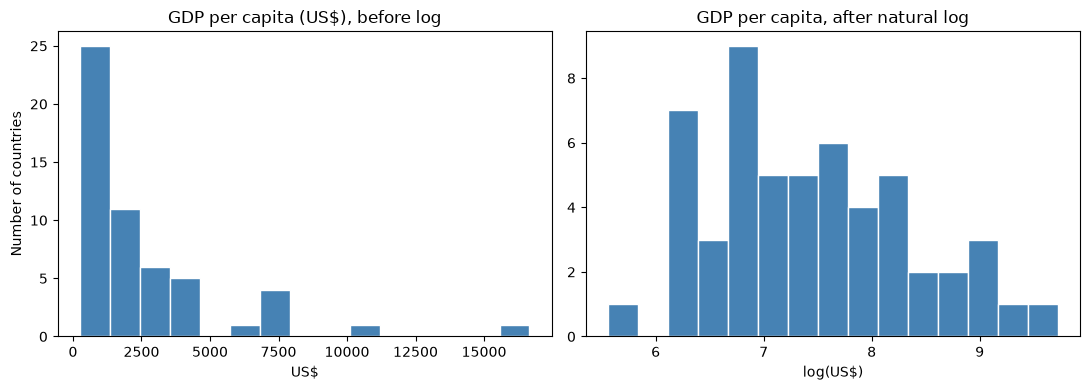

In [6]:
print("Skewness before log:", round(countries_clean["gdp_per_capita"].skew(), 2))

# GDP per capita is always positive, so the log is safe (no log of zero)
assert (countries_clean["gdp_per_capita"] > 0).all()
countries_clean["gdp_per_capita_log"] = np.log(countries_clean["gdp_per_capita"])

print("Skewness after log: ", round(countries_clean["gdp_per_capita_log"].skew(), 2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(countries_clean["gdp_per_capita"], bins=15, color="steelblue", edgecolor="white")
axes[0].set_title("GDP per capita (US$), before log")
axes[0].set_xlabel("US$")
axes[0].set_ylabel("Number of countries")
axes[1].hist(countries_clean["gdp_per_capita_log"], bins=15, color="steelblue", edgecolor="white")
axes[1].set_title("GDP per capita, after natural log")
axes[1].set_xlabel("log(US$)")
plt.tight_layout()
plt.savefig("../figures/gdp_log_transform.png", dpi=150)
plt.show()

## 5. Scaling

The eight indicators are in very different units: life expectancy is around 60 (years), internet users 0-90 (%), fertility 1-7 (births). K-Means groups points by Euclidean distance, so a feature with larger numbers would count for more just because of its units. `StandardScaler` rescales each feature to mean 0 and standard deviation 1 so all eight count equally.

In [7]:
# The 8 features the clustering will use: GDP enters as its log, the other seven as they are
model_cols = [
    "gdp_per_capita_log", "life_expectancy", "under5_mortality", "fertility_rate",
    "electricity_access", "internet_users", "urban_population", "agriculture_share_gdp",
]

scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(countries_clean[model_cols]),
    index=countries_clean.index,
    columns=model_cols,
)

# Check: every column should now have mean ~0 and std ~1.
# (pandas shows 1.01 because it divides by n-1; StandardScaler divides by n, which gives exactly 1.)
print(X_scaled.describe().loc[["mean", "std"]].round(2))

      gdp_per_capita_log  life_expectancy  under5_mortality  fertility_rate  \
mean               -0.00             0.00             -0.00            0.00   
std                 1.01             1.01              1.01            1.01   

      electricity_access  internet_users  urban_population  \
mean                0.00           -0.00             -0.00   
std                 1.01            1.01              1.01   

      agriculture_share_gdp  
mean                   0.00  
std                    1.01  


## 6. Why each step is needed

- **Averaging 2018-2022:** gives one stable row per country instead of five noisy ones, and reduces the effect of a missing or odd single year.
- **Dropping countries with more than 2 missing indicators:** a country with most of its data missing would be placed by guesses, not facts. In this data, no country breaks the rule, so none are dropped.
- **Median imputation:** K-Means cannot handle missing values. The median is a safe fill-in because it is not pulled around by extreme countries. Only four countries have gaps (6 values in total out of 432), so the effect on the result should be small. Still, those four countries are placed partly by an estimate.
- **Log of GDP per capita:** removes the extreme right skew so a few rich countries do not dominate the distance calculation.
- **Scaling (the most important step for K-Means):** K-Means works by distance, so without scaling, features with big numbers (like GDP in thousands of dollars, or percentages up to 100) would drown out features with small numbers (like fertility rate, 1-7). After scaling, each indicator has equal weight.

Note: the scaled table `X_scaled` is what goes into K-Means in the next block. I keep `countries_clean` (original units, imputed) to describe the clusters in real units afterwards.

---
# Choosing k and clustering

K-Means needs me to say how many clusters (k) I want. I should not guess, so I use two standard methods for k = 2 to 8:

- **Elbow method:** K-Means reports *inertia*, the total squared distance from each country to its cluster centre. Inertia always falls as k grows (more clusters means closer centres), so I look for the "elbow" where adding another cluster stops helping much.
- **Silhouette score:** for each country it compares how close it is to its own cluster against the nearest other cluster. It runs from -1 to 1 and higher means cleaner, better-separated clusters. Unlike inertia, it does not automatically improve as k grows, so it can point to a best k.

In [8]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 9)
inertias = []
silhouettes = []

for k in k_values:
    # n_init=10: run K-Means from 10 random starts and keep the best, so one unlucky start does not mislead
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(X_scaled, kmeans.labels_))

k_table = pd.DataFrame({
    "k": list(k_values),
    "inertia": inertias,
    "inertia drop from previous k": [np.nan] + [inertias[i - 1] - inertias[i] for i in range(1, len(inertias))],
    "silhouette": silhouettes,
}).set_index("k").round(3)
k_table

,inertia,inertia drop from previous k,silhouette
k,,,
2,219.336,NaN,0.412
3,170.469,48.866,0.265
4,142.375,28.094,0.265
5,124.534,17.841,0.217
6,115.692,8.842,0.184
7,102.265,13.427,0.193
8,93.743,8.522,0.208


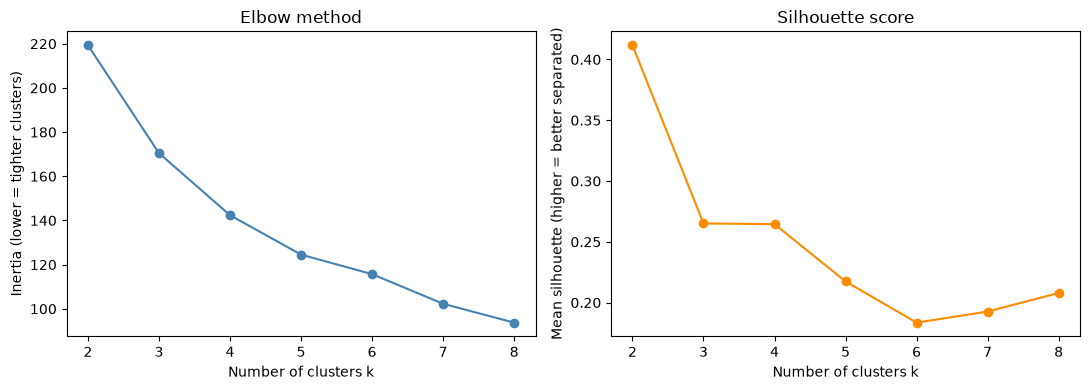

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(list(k_values), inertias, "o-", color="steelblue")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("Number of clusters k")
axes[0].set_ylabel("Inertia (lower = tighter clusters)")

axes[1].plot(list(k_values), silhouettes, "o-", color="darkorange")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of clusters k")
axes[1].set_ylabel("Mean silhouette (higher = better separated)")

plt.tight_layout()
plt.savefig("../figures/choosing_k.png", dpi=150)
plt.show()

## Choosing k: my reasoning

What the two methods show:
- **Silhouette** is highest at **k = 2** (0.412). It then drops to 0.265 for both k = 3 and k = 4, and keeps falling to about 0.18-0.21 for larger k.
- **Elbow:** inertia drops by 49 going from k = 2 to 3, by 28 from 3 to 4, by 18 from 4 to 5, and by only 9 from 5 to 6. The curve bends around k = 3-4 and is fairly flat after that. There is no sharp elbow, just a gradual bend.

**My choice: k = 3.** My reasoning:
1. The two methods do not agree perfectly, so I need a stated rule. Silhouette alone picks k = 2, but k = 2 splits the continent into just two big groups (18 and 36 countries), which is too coarse for my aim of seeing different development profiles. I therefore chose the best k among k >= 3, which is where the silhouette stays highest (k = 3 and k = 4 tie at 0.265) and the elbow is bending.
2. Between k = 3 and k = 4 the silhouette is tied, but k = 4 only adds a very small cluster (4 countries) and the elbow gain from 3 to 4 is smaller than from 2 to 3. With only 54 countries, I prefer the simpler model with more evenly sized clusters (14, 19 and 21 countries).

I accept that this is a judgement call, and k = 2 is a defensible alternative if I only wanted the cleanest split.

In [10]:
chosen_k = 3

kmeans = KMeans(n_clusters=chosen_k, n_init=10, random_state=42)
cluster_labels = kmeans.fit_predict(X_scaled)

# Store the cluster number next to each country. Numbers (0, 1, 2) are arbitrary names; I describe the clusters in the next block.
clusters = pd.Series(cluster_labels, index=X_scaled.index, name="cluster")

print("Silhouette for k =", chosen_k, ":", round(silhouette_score(X_scaled, cluster_labels), 3))
print()
print("Countries per cluster:")
print(clusters.value_counts().sort_index())

Silhouette for k = 3 : 0.265

Countries per cluster:
cluster
0    21
1    19
2    14
Name: count, dtype: int64


## Visualising the clusters with PCA

The clustering used 8 dimensions, which I cannot plot. **PCA** (principal component analysis) finds the two directions along which the countries vary the most, so I can plot them on a flat scatter. PCA is only used for the picture: K-Means was fitted on all 8 scaled features, not on these two.

In [11]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
pca_coords = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(pca_coords, index=X_scaled.index, columns=["PC1", "PC2"])
pca_df["cluster"] = clusters

# How much of the total variation do the two axes capture?
print("Explained variance ratio:", pca.explained_variance_ratio_.round(3))
print("Total for 2 components:  ", round(pca.explained_variance_ratio_.sum(), 3))

# Loadings: how much each original feature contributes to each axis
loadings = pd.DataFrame(pca.components_.T, index=model_cols, columns=["PC1", "PC2"]).round(2)
loadings

Explained variance ratio: [0.692 0.129]
Total for 2 components:   0.821


,PC1,PC2
gdp_per_capita_log,0.37,0.24
life_expectancy,0.34,-0.50
under5_mortality,-0.34,0.50
fertility_rate,-0.36,0.19
electricity_access,0.38,0.03
internet_users,0.39,0.18
urban_population,0.28,0.55
agriculture_share_gdp,-0.34,-0.26


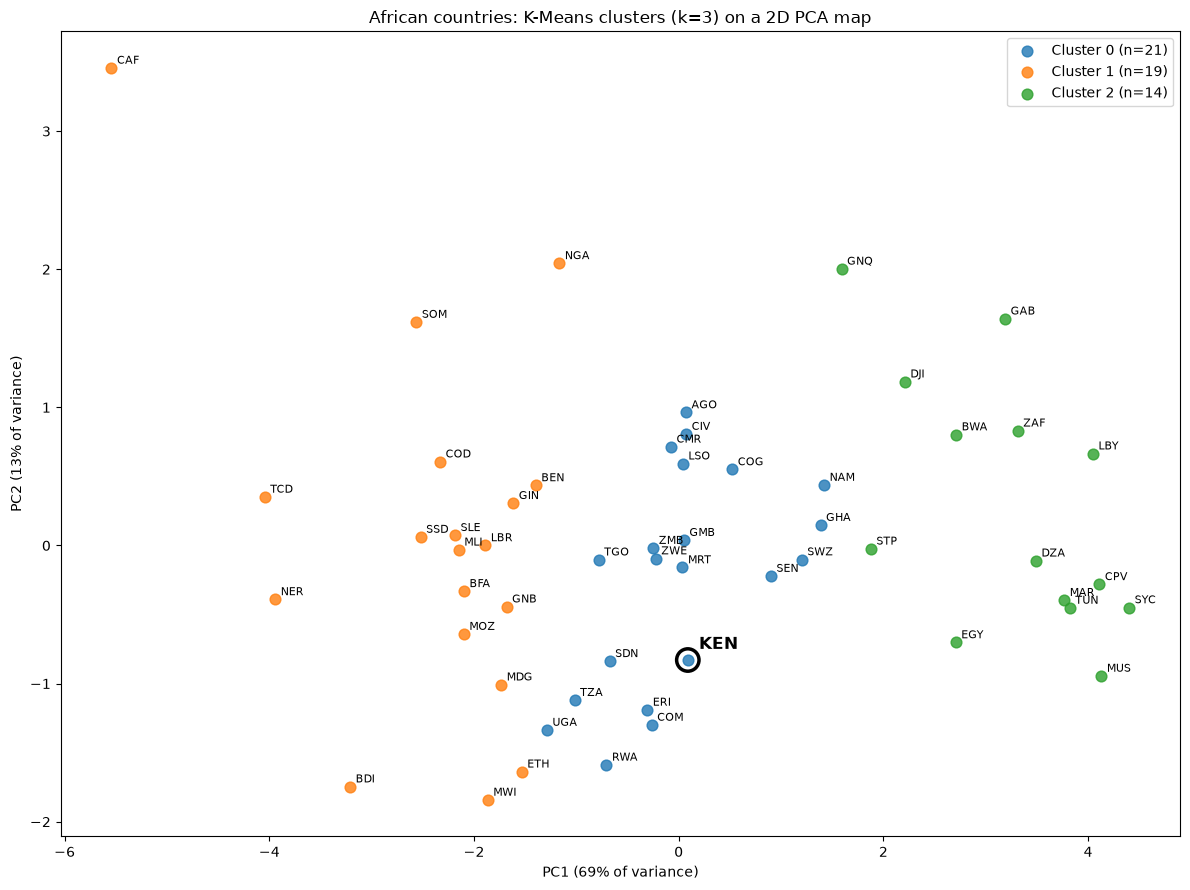

In [12]:
cluster_colors = {0: "tab:blue", 1: "tab:orange", 2: "tab:green"}

fig, ax = plt.subplots(figsize=(12, 9))

for cluster_id in range(chosen_k):
    members = pca_df[pca_df["cluster"] == cluster_id]
    ax.scatter(members["PC1"], members["PC2"], s=60, color=cluster_colors[cluster_id],
               alpha=0.8, label=f"Cluster {cluster_id} (n={len(members)})")

# Label every country with its ISO3 code
for iso3, row in pca_df.iterrows():
    if iso3 != "KEN":
        ax.annotate(iso3, (row["PC1"], row["PC2"]), xytext=(4, 3), textcoords="offset points", fontsize=8)

# Highlight Kenya: bigger marker with a black outline, and a bold label
kenya = pca_df.loc["KEN"]
ax.scatter(kenya["PC1"], kenya["PC2"], s=260, facecolors="none", edgecolors="black", linewidths=2.5, zorder=5)
ax.annotate("KEN", (kenya["PC1"], kenya["PC2"]), xytext=(8, 8), textcoords="offset points",
            fontsize=12, fontweight="bold")

ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.0f}% of variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.0f}% of variance)")
ax.set_title("African countries: K-Means clusters (k=3) on a 2D PCA map")
ax.legend()
plt.tight_layout()
plt.savefig("../figures/pca_clusters.png", dpi=150)
plt.show()

**Reading the PCA map**

- **The two axes keep 82% of the information** (PC1 69%, PC2 13%), so this 2D picture is a faithful summary of the 8-dimensional data. PC1 alone carries most of it.
- **PC1 is an overall "development level" axis.** Higher GDP, life expectancy, electricity access, internet use and urbanisation all push a country to the right, and higher child mortality, fertility and agriculture share push it to the left (see the loadings table: all eight loadings on PC1 have similar size, 0.28-0.39, with these signs). So moving from left to right means moving from less to more developed.
- **PC2 is harder to read** (13% of variance). It contrasts urbanisation and high child mortality (positive) with high life expectancy and agriculture (negative). I will not over-interpret it. Its main visible effect is spreading out a few unusual countries, for example the Central African Republic (CAF) at the top left, and Equatorial Guinea (GNQ) and Gabon (GAB) at the top right.
- **The three clusters line up along PC1:** Cluster 1 (orange) is on the left, Cluster 0 (blue) is in the middle and Cluster 2 (green) is on the right.
- **The clusters are not separate islands.** The boundary between Cluster 0 and Cluster 1 is a smooth continuum: for example TGO, SDN, TZA and UGA (blue) sit right next to orange countries. This matches the modest silhouette score of 0.265: the groups are useful ways to cut a continuous spectrum, not natural, sharply separated types.
- **Kenya (KEN)** sits in the middle of PC1 (about 0.1) and low on PC2, inside Cluster 0, close to Sudan (SDN), Tanzania (TZA), Eritrea (ERI) and Comoros (COM). Its low PC2 value reflects a large agriculture share and a smaller urban population than countries like Angola or Cameroon.

## Optional: t-SNE

t-SNE is another way to squeeze the data into 2D. It tries to keep each country close to its nearest neighbours. I include it only as a cross-check.

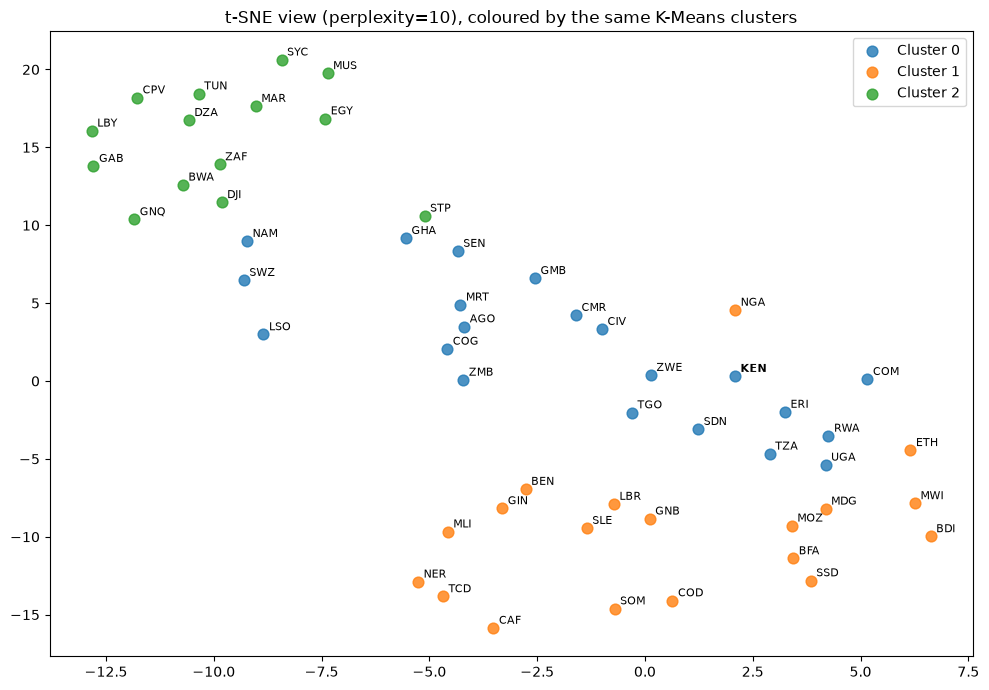

In [13]:
from sklearn.manifold import TSNE

# perplexity must be smaller than the number of points; ~10 suits 54 points (it is roughly "how many neighbours to consider")
tsne = TSNE(n_components=2, perplexity=10, init="pca", random_state=42)
tsne_coords = tsne.fit_transform(X_scaled)
tsne_df = pd.DataFrame(tsne_coords, index=X_scaled.index, columns=["dim1", "dim2"])
tsne_df["cluster"] = clusters

fig, ax = plt.subplots(figsize=(10, 7))
for cluster_id in range(chosen_k):
    members = tsne_df[tsne_df["cluster"] == cluster_id]
    ax.scatter(members["dim1"], members["dim2"], s=60, color=cluster_colors[cluster_id],
               alpha=0.8, label=f"Cluster {cluster_id}")
for iso3, row in tsne_df.iterrows():
    ax.annotate(iso3, (row["dim1"], row["dim2"]), xytext=(4, 3), textcoords="offset points", fontsize=8,
                fontweight="bold" if iso3 == "KEN" else "normal")
ax.set_title("t-SNE view (perplexity=10), coloured by the same K-Means clusters")
ax.legend()
plt.tight_layout()
plt.savefig("../figures/tsne_clusters.png", dpi=150)
plt.show()

**Why I prefer PCA for about 50 points:**
- PCA is a simple linear projection, so the axes have a meaning I can read from the loadings table. t-SNE axes have no meaning.
- With only 54 points, t-SNE is unstable: the picture changes with the perplexity and random seed, and the distances between separate blobs are not reliable.
- PCA is deterministic (same answer each time) and tells me how much variance each axis keeps. t-SNE does not.

So I use PCA as the main picture and t-SNE only to check that the same groups appear.